# Import the libraries and dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

%matplotlib inline

In [2]:
df = pd.read_csv('data/penguins.csv')
df = df.dropna().reset_index(drop=True)
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


# How many species are really in here?

Unlike the tips dataset, the penguins dataset comes with a ground-truth `species` column. We'll pretend we don't know it while clustering, then use it afterwards to check our work.

In [3]:
df['species'].value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

# Select features and scale them

We'll cluster on all four body measurements: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, and `body_mass_g`.

k-Means decides which points belong together using straight-line distance. `body_mass_g` is measured in the thousands while the bill measurements are in the tens, so without rescaling, body mass would completely dominate the distance calculation and drown out the other features. `StandardScaler` puts every feature on the same footing (mean 0, standard deviation 1) before we cluster.

In [4]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[-0.89604189,  0.7807321 , -1.42675157, -0.56847478],
       [-0.82278787,  0.11958397, -1.06947358, -0.50628618],
       [-0.67627982,  0.42472926, -0.42637319, -1.1903608 ],
       [-1.33556603,  1.0858774 , -0.56928439, -0.94160639],
       [-0.85941488,  1.74702554, -0.78365118, -0.69285199]])

# Run k-Means with k = 3

We know there are 3 penguin species (Adelie, Chinstrap, Gentoo) in this dataset, so we'll tell `KMeans` to look for exactly `k = 3` groups and see whether it rediscovers those same species purely from body measurements -- without ever being told the species label.

In [5]:
model = KMeans(n_clusters=3, n_init='auto', random_state=42)
model.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 4)","[

In [6]:
df['cluster'] = model.labels_
df['cluster'].value_counts().sort_index()

cluster
0    129
1    119
2     85
Name: count, dtype: int64

# Visualize: actual species vs. discovered clusters

We clustered using all four scaled measurements, but we can still visualize the result in 2D using `bill_length_mm` and `bill_depth_mm`, since those two alone separate the species quite well visually.

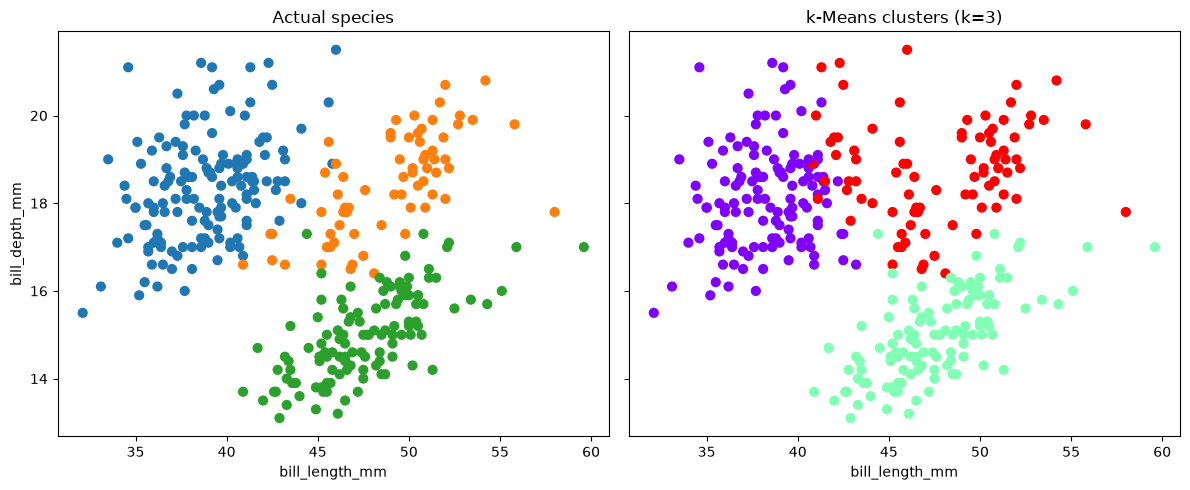

In [7]:
species_colors = {'Adelie': 'tab:blue', 'Chinstrap': 'tab:orange', 'Gentoo': 'tab:green'}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

axes[0].scatter(df['bill_length_mm'], df['bill_depth_mm'], c=df['species'].map(species_colors), s=40)
axes[0].set_title('Actual species')
axes[0].set_xlabel('bill_length_mm')
axes[0].set_ylabel('bill_depth_mm')

axes[1].scatter(df['bill_length_mm'], df['bill_depth_mm'], c=df['cluster'], cmap='rainbow', s=40)
axes[1].set_title('k-Means clusters (k=3)')
axes[1].set_xlabel('bill_length_mm')

plt.tight_layout()
plt.show()

# How well do the clusters match the species?

k-Means assigns arbitrary cluster numbers (0, 1, 2) -- it has no idea those correspond to "Adelie", "Chinstrap", or "Gentoo". To check how well the clustering lines up with the real species, we build a crosstab of cluster vs. species, then map each cluster to whichever species is most common inside it.

In [8]:
pd.crosstab(df['cluster'], df['species'])

species,Adelie,Chinstrap,Gentoo
cluster,,,
0,124,5,0
1,0,0,119
2,22,63,0


In [9]:
cluster_to_species = df.groupby('cluster')['species'].agg(lambda s: s.value_counts().idxmax())
print('Cluster -> majority species:')
print(cluster_to_species)

df['predicted_species'] = df['cluster'].map(cluster_to_species)
accuracy = (df['predicted_species'] == df['species']).mean()
print(f"\nCluster-to-species match rate: {accuracy:.1%}")

Cluster -> majority species:
cluster
0       Adelie
1       Gentoo
2    Chinstrap
Name: species, dtype: str

Cluster-to-species match rate: 91.9%


# Bonus: does scaling actually matter?

Let's rerun k-Means on the *unscaled* features to see what happens when `body_mass_g` is allowed to dominate the distance calculation.

In [10]:
model_unscaled = KMeans(n_clusters=3, n_init='auto', random_state=42)
unscaled_clusters = model_unscaled.fit_predict(X)

cluster_to_species_unscaled = (
    pd.Series(unscaled_clusters, name='cluster')
    .to_frame()
    .assign(species=df['species'])
    .groupby('cluster')['species']
    .agg(lambda s: s.value_counts().idxmax())
)
predicted_unscaled = pd.Series(unscaled_clusters).map(cluster_to_species_unscaled)
accuracy_unscaled = (predicted_unscaled.values == df['species'].values).mean()

print(f"Match rate without scaling: {accuracy_unscaled:.1%}")
print(f"Match rate with scaling:    {accuracy:.1%}")

Match rate without scaling: 67.9%
Match rate with scaling:    91.9%


## Takeaways

- k-Means found 3 clusters that line up with the real species surprisingly well -- all without ever seeing the `species` column.
- The match isn't perfect: Adelie and Chinstrap overlap a bit in body measurements, so a handful of penguins land in the "wrong" cluster.
- Scaling the features before clustering made a real difference, because k-Means is distance-based and `body_mass_g`'s much larger numeric scale would otherwise overwhelm the bill and flipper measurements.
- The cluster-to-species match rate is an *after-the-fact* sanity check, not something k-Means optimizes for -- it never had access to the species labels while fitting.